**Step 1:Data Loading for Bitcoin Market Sentiment Dataset**

In [ ]:
!pip install cudf-cu12 cuml-cu12 --extra-index-url=https://pypi.nvidia.com

Looking in indexes: https://pypi.org/simple, https://pypi.nvidia.com


In [ ]:
import cudf

# 1. Load Data directly into GPU memory
fg_df = cudf.read_csv('/content/drive/MyDrive/Primetrade.ai Task Assesssment/fear_greed_index.csv')
hist_df = cudf.read_csv('/content/drive/MyDrive/Primetrade.ai Task Assesssment/historical_data.csv')

**Step 2:Overview**

fear and greed dataset

In [ ]:
# View the first 5 rows
print(fg_df.head())
print("\n--- Data Types ---")
# Note: cuDF uses .dtypes instead of pandas' .info()
print(fg_df.dtypes)
print(f"\nShape: {fg_df.shape}")

    timestamp  value classification        date
0  1517463000     30           Fear  2018-02-01
1  1517549400     15   Extreme Fear  2018-02-02
2  1517635800     40           Fear  2018-02-03
3  1517722200     24   Extreme Fear  2018-02-04
4  1517808600     11   Extreme Fear  2018-02-05

--- Data Types ---
timestamp          int64
value              int64
classification    object
date              object
dtype: object

Shape: (2644, 4)


In [ ]:
print(fg_df.describe())

          timestamp        value
count  2.644000e+03  2644.000000
mean   1.631899e+09    46.981089
std    6.597967e+07    21.827680
min    1.517463e+09     5.000000
25%    1.574811e+09    28.000000
50%    1.631900e+09    46.000000
75%    1.688989e+09    66.000000
max    1.746164e+09    95.000000


In [ ]:
print(fg_df.isnull().sum())

timestamp         0
value             0
classification    0
date              0
dtype: int64


In [ ]:
print(fg_df.info)

<bound method DataFrame.info of        timestamp  value classification        date
0     1517463000     30           Fear  2018-02-01
1     1517549400     15   Extreme Fear  2018-02-02
2     1517635800     40           Fear  2018-02-03
3     1517722200     24   Extreme Fear  2018-02-04
4     1517808600     11   Extreme Fear  2018-02-05
...          ...    ...            ...         ...
2639  1745818200     54        Neutral  2025-04-28
2640  1745904600     60          Greed  2025-04-29
2641  1745991000     56          Greed  2025-04-30
2642  1746077400     53        Neutral  2025-05-01
2643  1746163800     67          Greed  2025-05-02

[2644 rows x 4 columns]>


historical trade dataset

In [ ]:
# View the first 5 rows
print(hist_df.head())
print("\n--- Data Types ---")
print(hist_df.dtypes)
print(f"\nShape: {hist_df.shape}")

                                      Account  Coin  Execution Price  \
0  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9769   
1  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9800   
2  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9855   
3  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9874   
4  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9894   

   Size Tokens  Size USD Side     Timestamp IST  Start Position Direction  \
0       986.87   7872.16  BUY  02-12-2024 22:50        0.000000       Buy   
1        16.00    127.68  BUY  02-12-2024 22:50      986.524596       Buy   
2       144.09   1150.63  BUY  02-12-2024 22:50     1002.518996       Buy   
3       142.98   1142.04  BUY  02-12-2024 22:50     1146.558564       Buy   
4         8.73     69.75  BUY  02-12-2024 22:50     1289.488521       Buy   

   Closed PnL                                   Transaction Hash     Order ID  \
0         0.0  0xec0945

In [ ]:
print(hist_df.isnull().sum())

Account             0
Coin                0
Execution Price     0
Size Tokens         0
Size USD            0
Side                0
Timestamp IST       0
Start Position      0
Direction           0
Closed PnL          0
Transaction Hash    0
Order ID            0
Crossed             0
Fee                 0
Trade ID            0
Timestamp           0
dtype: int64


In [ ]:
print(hist_df.describe())

       Execution Price   Size Tokens      Size USD  Start Position  \
count     38559.000000  3.855900e+04  3.855900e+04    3.855900e+04   
mean      34909.564295  1.485362e+04  1.705296e+04   -1.276603e+03   
std       43537.905539  2.017447e+05  7.868039e+04    6.804436e+05   
min           0.000010  1.000000e-05  0.000000e+00   -1.433463e+07   
25%           3.239450  1.377000e-01  3.861600e+02   -9.350305e+01   
50%        2365.600000  2.900000e+00  1.499540e+03    4.127400e+00   
75%       85204.000000  1.980069e+02  9.999530e+03    5.886904e+02   
max      108410.000000  1.150000e+07  3.921431e+06    1.150000e+07   

          Closed PnL      Order ID           Fee      Trade ID     Timestamp  
count   38559.000000  3.855900e+04  38559.000000  3.855900e+04  3.855900e+04  
mean      105.823424  6.713601e+10      3.426082  5.646089e+14  1.737111e+12  
std      1614.561944  2.327576e+10     13.570411  3.254708e+14  1.133689e+10  
min   -117990.104100  7.478562e+09     -1.175712  0.0

In [ ]:
print(hist_df.info)

<bound method DataFrame.info of                                           Account   Coin  Execution Price  \
0      0xae5eacaf9c6b9111fd53034a602c192a04e082ed   @107         7.976900   
1      0xae5eacaf9c6b9111fd53034a602c192a04e082ed   @107         7.980000   
2      0xae5eacaf9c6b9111fd53034a602c192a04e082ed   @107         7.985500   
3      0xae5eacaf9c6b9111fd53034a602c192a04e082ed   @107         7.987400   
4      0xae5eacaf9c6b9111fd53034a602c192a04e082ed   @107         7.989400   
...                                           ...    ...              ...   
38554  0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4  HYPER         0.235300   
38555  0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4  HYPER         0.233770   
38556  0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4    BIO         0.071860   
38557  0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4    BIO         0.073149   
38558  0x75f7eeb85dc639d5e99c78f95393aa9a5f1170d4    BIO         0.073149   

       Size Tokens  Size USD  Side     Time

**Step 3:Exploratory Data Analysis**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')
from cuml.cluster import KMeans
from cuml.manifold import UMAP
from cuml.preprocessing import StandardScaler

In [ ]:
plt.style.use('dark_background')
sns.set_palette("husl")

**1.Interactive Fear & Greed Trend**

This plots the pure sentiment cycle over time. Plotly allows you to zoom and hover.

In [ ]:
fig1 = px.line(fg_df, x='date', y='value', color='classification',
               title='1. Interactive Fear & Greed Index Over Time')
fig1.show()

**2.PnL Distribution (Fat-Tail Analysis)**

Standard EDA showing how trading returns are distributed. We use a log scale because crypto trading usually has a massive amount of small trades and a few massive outliers.

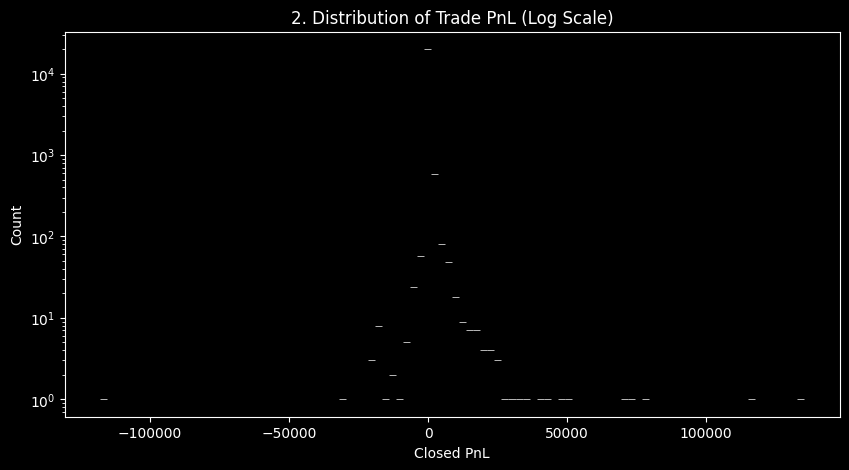

In [ ]:
plt.figure(figsize=(10, 5))
closed_pnl_cpu = hist_df[hist_df['Closed PnL'] != 0]['Closed PnL'].to_pandas()
sns.histplot(closed_pnl_cpu, bins=100, color='cyan', log_scale=(False, True))

plt.title('2. Distribution of Trade PnL (Log Scale)')
plt.xlabel('Closed PnL')
plt.ylabel('Count')
plt.show()

In [ ]:
closed_pnl_data = hist_df[hist_df['Closed PnL'] != 0]['Closed PnL'].to_pandas()

fig_pnl = px.histogram(
    closed_pnl_data,
    x="Closed PnL",
    nbins=100,
    title="2. Distribution of Trade PnL (Log Scale)",
    labels={"Closed PnL": "Closed PnL (USD)"},
    color_discrete_sequence=['cyan'],
    log_y=True # We keep the log scale because crypto returns have massive outliers
)

fig_pnl.update_layout(
    template="plotly_dark",
    xaxis_title="Closed PnL",
    yaxis_title="Count (Log Scale)",
    showlegend=False
)

fig_pnl.show()

**3.Trade Size vs Fee Execution**

Standard EDA to check if fees scale linearly with size, or if there are anomalies/slippage.

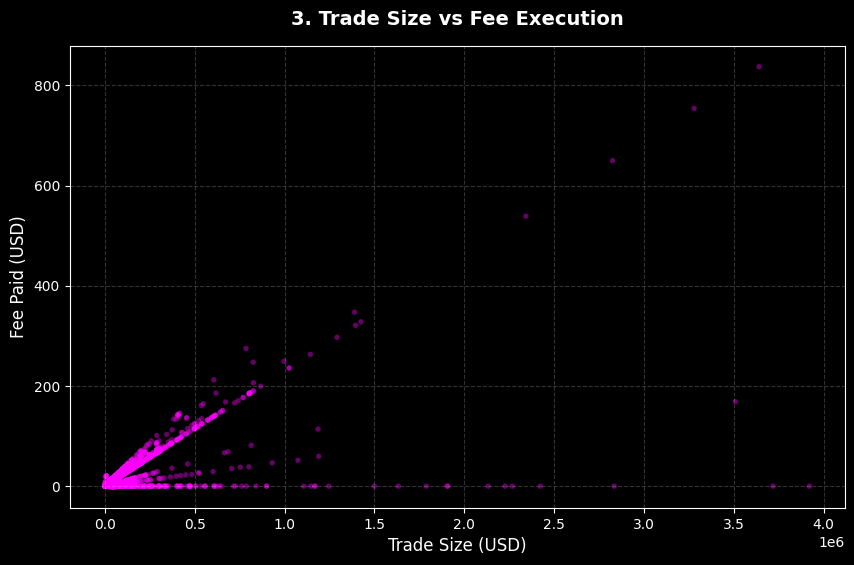

In [ ]:
# 1. Safely hand off ONLY the required columns to the CPU for plotting
# Using .to_numpy() is slightly faster and lighter than .to_pandas() here
size_cpu = hist_df['Size USD'].to_numpy()
fee_cpu = hist_df['Fee'].to_numpy()

# 2. Set up the figure size
plt.figure(figsize=(10, 6))

# 3. Create the scatter plot
# alpha=0.4 handles the dense overlapping points
# s=15 controls the size of the markers
plt.scatter(size_cpu, fee_cpu, alpha=0.4, color='magenta', edgecolors='none', s=15)

plt.title('3. Trade Size vs Fee Execution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Trade Size (USD)', fontsize=12)
plt.ylabel('Fee Paid (USD)', fontsize=12)
plt.grid(True, alpha=0.2, linestyle='--')

plt.show()

In [ ]:
import plotly.express as px

plot_3_data = hist_df[['Size USD', 'Fee']].to_pandas()
fig_scatter = px.scatter(
    plot_3_data,
    x="Size USD",
    y="Fee",
    title="3. Trade Size vs Fee Execution",
    labels={"Size USD": "Trade Size (USD)", "Fee": "Fee Paid (USD)"},
    opacity=0.4, # Makes overlapping dense areas visible
    color_discrete_sequence=['magenta']
)

fig_scatter.update_layout(
    template="plotly_dark",
    xaxis_title="Trade Size (USD)",
    yaxis_title="Fee Paid (USD)"
)

fig_scatter.show()

**4.Market Regime Detection (K-Means)**

Instead of just "Fear" vs "Greed", we engineer a momentum feature (7-day change) to group the market into active 'Regimes' (e.g., Sideways Chop, Rapid Crash, Bull Rally)

In [ ]:
import pandas as pd
import plotly.express as px
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Safely ensure data is in standard RAM (Pandas) to prevent crashes
# If fg_df is already a pandas DataFrame, this just copies it. If it's cuDF, it converts it.
fg_cpu = fg_df.to_pandas() if hasattr(fg_df, 'to_pandas') else fg_df.copy()

# 2. Feature Engineering: Calculate 7-day Momentum
fg_cpu['momentum_7d'] = fg_cpu['value'].diff(7).fillna(0)

# 3. Isolate the features
features = fg_cpu[['value', 'momentum_7d']]

# CRITICAL STEP: Standardize the data.
# K-Means is distance-based. If we don't scale, the 0-100 Value will completely overpower the -20 to +20 Momentum.
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# 4. Train the K-Means algorithm to find 3 distinct market regimes
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
fg_cpu['Market_Regime'] = kmeans.fit_predict(scaled_features)

# Convert the numerical cluster IDs (0, 1, 2) to strings so Plotly treats them as distinct categories
fg_cpu['Market_Regime'] = fg_cpu['Market_Regime'].astype(str)

# 5. Visualize the regimes over time
fig_regime = px.scatter(
    fg_cpu,
    x='date',
    y='value',
    color='Market_Regime',
    title="4. K-Means Market Regimes (Value + Momentum)",
    labels={"value": "Fear & Greed Index", "date": "Date", "Market_Regime": "Regime Cluster"},
    color_discrete_sequence=['#00CC96', '#EF553B', '#AB63FA'], # Clean high-contrast colors
    opacity=0.8
)

# Apply the dark-mode aesthetic
fig_regime.update_layout(template="plotly_dark")
fig_regime.show()

**5. UMAP Trader Archetype Clustering**

Group event-level trade data into behavioral profiles for each account

In [ ]:
import cudf
import cupy as cp
from cuml.preprocessing import StandardScaler
from cuml.manifold import UMAP
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

# --- 1. cuDF: Native VRAM Aggregation ---
# Ensure we are operating on the GPU dataframe
if not isinstance(hist_df, cudf.DataFrame):
    hist_gpu = cudf.from_pandas(hist_df)
else:
    hist_gpu = hist_df.copy()

# Recalculate profitability flag just in case
hist_gpu['Is_Profitable'] = (hist_gpu['Closed PnL'] > 0).astype('float32')

# Aggregate the millions of rows into unique trader profiles
trader_stats_gpu = hist_gpu.groupby('Account').agg({
    'Closed PnL': 'sum',
    'Size USD': 'mean',
    'Account': 'count',
    'Is_Profitable': 'mean'
})
trader_stats_gpu.columns = ['Total_PnL', 'Avg_Size', 'Trade_Count', 'Win_Rate']
trader_stats_gpu = trader_stats_gpu.reset_index()

# Filter out the noise (traders with 5 or fewer trades)
active_traders_gpu = trader_stats_gpu[trader_stats_gpu['Trade_Count'] > 5].copy()

# --- 2. CuPy: Memory-Optimized Matrix Extraction ---
# Extract the 4 behavioral dimensions into a continuous CuPy array for maximum C++ efficiency
features_to_cluster = ['Total_PnL', 'Avg_Size', 'Trade_Count', 'Win_Rate']
feature_matrix_cupy = cp.ascontiguousarray(
    active_traders_gpu[features_to_cluster].to_cupy(),
    dtype=cp.float32
)

# --- 3. cuML: High-Performance Dimensionality Reduction ---
# Scale the data so massive PnL numbers don't overpower the win rate
scaler = StandardScaler()
scaled_matrix_cupy = scaler.fit_transform(feature_matrix_cupy)

# Initialize and train UMAP entirely in VRAM
reducer = UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embeddings_cupy = reducer.fit_transform(scaled_matrix_cupy)

# Map the new 2D coordinates back into the cuDF DataFrame
active_traders_gpu['UMAP_X'] = embeddings_cupy[:, 0]
active_traders_gpu['UMAP_Y'] = embeddings_cupy[:, 1]

# --- 4. The CPU Bridge: Graceful Handoff ---
# Pull ONLY the summarized trader profiles and their new X/Y coordinates across the PCIe bus
plot_df = active_traders_gpu.to_pandas()

# --- 5. Interactive Visualization ---
fig = px.scatter(
    plot_df,
    x='UMAP_X',
    y='UMAP_Y',
    color='Win_Rate',
    size='Trade_Count',
    hover_data=['Account', 'Total_PnL', 'Avg_Size'],
    title='5. Fully Optimized RAPIDS UMAP (Trader Archetypes)',
    color_continuous_scale='RdYlGn'
)

fig.update_layout(template="plotly_dark")
fig.show()

**STEP 4:RELATION BETWEEN Trader Performance and Market Sentiment with Visualization(Merge+Visual)**

In [ ]:
import pandas as pd
import cudf
import plotly.express as px
import plotly.graph_objects as go

# --- 1. Data Cleaning & Alignment (The Bulletproof Way) ---

# A. Pull the data back to the CPU temporarily
hist_cpu = hist_gpu.to_pandas()
fg_cpu = fg_gpu.to_pandas()

# B. Use standard Pandas to parse the dates (it handles mixed string formats perfectly)
hist_cpu['Timestamp IST'] = pd.to_datetime(hist_cpu['Timestamp IST'], format='mixed', dayfirst=True)
fg_cpu['date'] = pd.to_datetime(fg_cpu['date'], format='mixed')

# C. Floor to the daily level on the CPU
hist_cpu['date'] = hist_cpu['Timestamp IST'].dt.floor('D')
fg_cpu['date'] = fg_cpu['date'].dt.floor('D')

# D. Send the perfectly formatted datetime objects back to the GPU
hist_gpu = cudf.from_pandas(hist_cpu)
fg_gpu = cudf.from_pandas(fg_cpu)

# --- 2. The Great Merge ---
# Now that both tables have identical GPU datetime types, the merge will be instant
merged_gpu = hist_gpu.merge(fg_gpu[['date', 'value', 'classification']], on='date', how='inner')

# --- 3. Micro Feature Engineering (Trade Level) ---
merged_gpu['Is_Profitable'] = (merged_gpu['Closed PnL'] > 0).astype('float32')

# --- 4. Macro Feature Engineering (Daily Level) ---
daily_macro_gpu = merged_gpu.groupby(['date', 'value', 'classification']).agg({
    'Closed PnL': 'sum',
    'Size USD': 'sum',
    'Account': 'count',
    'Is_Profitable': 'mean'
}).reset_index()

daily_macro_gpu.columns = ['date', 'Sentiment_Value', 'Classification', 'Daily_PnL', 'Total_Volume', 'Total_Trades', 'Win_Rate']

In [ ]:
daily_macro_gpu

,date,Sentiment_Value,Classification,Daily_PnL,Total_Volume,Total_Trades,Win_Rate
0,2024-05-12,56,Greed,0.000000,45004.64,10,0.000000
1,2024-06-29,30,Fear,1842.738325,223530.97,17,0.764706
2,2024-08-02,57,Greed,0.000000,295967.16,36,0.000000
3,2024-11-07,77,Extreme Greed,628.962460,60628.85,2,0.500000
4,2025-04-16,29,Fear,57782.299326,35061042.81,1047,0.400191
...,...,...,...,...,...,...,...
379,2024-06-26,46,Neutral,4197.732182,364194.84,31,0.677419
380,2025-02-15,50,Neutral,4346.743973,596265.60,56,0.571429
381,2024-05-04,67,Greed,0.000000,53999.34,6,0.000000
382,2025-01-23,75,Extreme Greed,6749.134920,1475987.52,82,0.268293


In [ ]:
# --- Bridge the aggregated data back to CPU for Plotly ---
daily_macro_cpu = daily_macro_gpu.to_pandas()
merged_cpu = merged_gpu[['Closed PnL', 'classification']].to_pandas()

# --- Plot 1: Macro Bubble Chart ---
fig1 = px.scatter(
    daily_macro_cpu,
    x='Sentiment_Value',
    y='Daily_PnL',
    size='Total_Volume',
    color='Classification',
    hover_data=['date', 'Win_Rate', 'Total_Trades'],
    title="1. Macro: Daily Market PnL vs. Fear & Greed Index",
    labels={"Sentiment_Value": "Fear & Greed Index (0-100)", "Daily_PnL": "Total Daily PnL (USD)"},
    color_discrete_map={
        "Extreme Fear": "#EF553B",
        "Fear": "#FFA15A",
        "Neutral": "#FECB52",
        "Greed": "#00CC96",
        "Extreme Greed": "#19D3F3"
    },
    opacity=0.7
)

# Add a horizontal line at $0 PnL for visual reference
fig1.add_hline(y=0, line_dash="dash", line_color="white", opacity=0.5)
fig1.update_layout(template="plotly_dark")
fig1.show()

# --- Plot 2: Micro Box Plot (Outlier Detection) ---
fig2 = px.box(
    merged_cpu,
    x='classification',
    y='Closed PnL',
    color='classification',
    title="2. Micro: Trade PnL Distribution by Market Sentiment",
    labels={"classification": "Market Sentiment", "Closed PnL": "Individual Trade PnL (USD)"},
    color_discrete_map={
        "Extreme Fear": "#EF553B",
        "Fear": "#FFA15A",
        "Neutral": "#FECB52",
        "Greed": "#00CC96",
        "Extreme Greed": "#19D3F3"
    }
)

# Use a log scale because massive outlier trades will crush the standard axis
fig2.update_layout(template="plotly_dark")
fig2.show()

**STEP 5:Data Cleaning for merged Data and Collecting new combined csv**

In [ ]:
import cudf
import cupy as cp
import os
# 1. Load the raw data directly into GPU VRAM
fg_gpu = cudf.read_csv("/content/drive/MyDrive/Primetrade.ai Task Assesssment/fear_greed_index.csv")
hist_gpu = cudf.read_csv("/content/drive/MyDrive/Primetrade.ai Task Assesssment/historical_data.csv")

print("Processing and standardizing dates on CUDA Cores...")
# 2. Clean the Fear & Greed Dates (Explicitly providing the format for cuDF)
fg_gpu['date'] = cudf.to_datetime(fg_gpu['date'], format='%Y-%m-%d')
fg_gpu['date'] = fg_gpu['date'].dt.floor('D')
# Sort chronologically so momentum calculates correctly
fg_gpu = fg_gpu.sort_values('date').reset_index(drop=True)

# 3. Clean the Trade Dates
temp_dates_cpu = hist_gpu['Timestamp IST'].to_pandas()
clean_dates_cpu = pd.to_datetime(temp_dates_cpu, format='mixed', dayfirst=True)
hist_gpu['Timestamp IST'] = cudf.from_pandas(clean_dates_cpu)
hist_gpu['date'] = hist_gpu['Timestamp IST'].dt.floor('D')

print("Extracting Micro (Trade) Features using CuPy...")
# 4. Target Variable for ML
# We use CuPy (cp.where) to rapidly evaluate the PnL array natively on the GPU cores
pnl_array = hist_gpu['Closed PnL'].to_cupy()
hist_gpu['Is_Profitable'] = cp.where(pnl_array > 0, 1, 0).astype('int32')

# Time-based numerical features for the ML model
hist_gpu['Trade_Hour'] = hist_gpu['Timestamp IST'].dt.hour
hist_gpu['Trade_DayOfWeek'] = hist_gpu['Timestamp IST'].dt.dayofweek

print("Extracting Macro (Sentiment) Features...")
# 5. Calculate 7-day momentum of Fear & Greed
fg_gpu['Sentiment_Momentum_7d'] = fg_gpu['value'].diff(7).fillna(0)

print("Merging Datasets in VRAM...")
# 6. Merge the macro sentiment onto the micro trade data based on the matching 'date'
columns_to_merge = ['date', 'value', 'classification', 'Sentiment_Momentum_7d']
merged_gpu = hist_gpu.merge(fg_gpu[columns_to_merge], on='date', how='inner')

# Rename columns so they are clean for the ML model
merged_gpu = merged_gpu.rename(columns={
    'value': 'Sentiment_Value',
    'classification': 'Sentiment_Class'
})

# Drop rows with missing critical data
critical_cols = ['Closed PnL', 'Size USD', 'Fee', 'Sentiment_Value']
merged_gpu = merged_gpu.dropna(subset=critical_cols)

print("Saving the Engineered Dataset to Primetrade folder...")

# 6. Define the target folder and file name
folder_name = "Primetrade"
output_filename = f"{folder_name}/ml_ready_trading_data.csv"

# Create the folder if it doesn't already exist
if not os.path.exists(folder_name):
    os.makedirs(folder_name)
    print(f"Created new folder: {folder_name}")

# Save the final ML-ready dataset directly into the folder
merged_gpu.to_csv(output_filename, index=False)

print("-" * 40)
print(f"Successfully saved to {output_filename}!")
print(f"Total Rows: {len(merged_gpu)} | Total Columns: {len(merged_gpu.columns)}")
print("-" * 40)

Processing and standardizing dates on CUDA Cores...
Extracting Micro (Trade) Features using CuPy...
Extracting Macro (Sentiment) Features...
Merging Datasets in VRAM...
Saving the Engineered Dataset to Primetrade folder...
Created new folder: Primetrade
----------------------------------------
Successfully saved to Primetrade/ml_ready_trading_data.csv!
Total Rows: 38553 | Total Columns: 23
----------------------------------------


**STEP 6:TRAINED A ML MODEL ON MERGED DATASET**

In [ ]:
import cudf
import cupy as cp
import xgboost as xgb
from cuml.model_selection import train_test_split
from cuml.metrics import accuracy_score, roc_auc_score, log_loss, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import CalibratedClassifierCV
import plotly.figure_factory as ff
import warnings
warnings.filterwarnings('ignore')

print(" Loading Data into VRAM via cuDF...")
df_gpu = cudf.read_csv("/content/drive/MyDrive/Primetrade.ai Task Assesssment/ml_ready_trading_data.csv")

# Ensure all features are float32 for maximum Tensor Core throughput
features = ['Size USD', 'Fee', 'Trade_Hour', 'Sentiment_Value', 'Sentiment_Momentum_7d']
target = 'Is_Profitable'

X_gpu = df_gpu[features].astype('float32')
y_gpu = df_gpu[target].astype('int32')

print(" Splitting data on GPU using cuML...")
# cuML train_test_split happens instantly without memory copying
X_train, X_test, y_train, y_test = train_test_split(X_gpu, y_gpu, test_size=0.2, random_state=42)

print("Bridging scaffolding to CPU for Scikit-Learn Meta-Estimators...")
# We hand off pointers to Pandas JUST for the Scikit-Learn loop wrappers.
X_train_cpu = X_train.to_pandas()
y_train_cpu = y_train.to_pandas()
X_test_cpu = X_test.to_pandas()

print(" Running Grid Search CV on CUDA Cores...")
base_xgb = xgb.XGBClassifier(tree_method='hist', device='cuda', random_state=42, eval_metric='logloss')

param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1],
    'n_estimators': [100, 200]
}

# n_jobs=1 prevents multi-threading from crashing the VRAM allocation
grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    cv=3,
    scoring='roc_auc',
    verbose=1,
    n_jobs=1
)

grid_search.fit(X_train_cpu, y_train_cpu)
best_xgb = grid_search.best_estimator_
print(f"Best Hyperparameters Found: {grid_search.best_params_}")

print("Calibrating Probabilities for Real-World Risk Management...")
calibrated_clf = CalibratedClassifierCV(best_xgb, method='sigmoid', cv=3)
calibrated_clf.fit(X_train_cpu, y_train_cpu)

print("Generating Predictions...")
# Predictions come out of the CalibratedClassifier as standard NumPy arrays
y_pred_cpu = calibrated_clf.predict(X_test_cpu)
y_prob_cpu = calibrated_clf.predict_proba(X_test_cpu)[:, 1]

print(" Transferring Predictions back to VRAM for cuML Metrics...")
y_test_gpu = cp.asarray(y_test)
y_pred_gpu = cp.asarray(y_pred_cpu)
y_prob_gpu = cp.asarray(y_prob_cpu)

# --- Pure GPU Evaluation Metrics ---
acc_gpu = accuracy_score(y_test_gpu, y_pred_gpu)
roc_auc_gpu = roc_auc_score(y_test_gpu, y_prob_gpu)
log_loss_gpu = log_loss(y_test_gpu, y_prob_gpu)
cm_gpu = confusion_matrix(y_test_gpu, y_pred_gpu)

# Extract TP, TN, FP, FN directly from the CuPy matrix
TN = cm_gpu[0, 0]
FP = cm_gpu[0, 1]
FN = cm_gpu[1, 0]
TP = cm_gpu[1, 1]

# Calculate custom metrics using CuPy mathematics
precision_gpu = TP / (TP + FP) if (TP + FP) > 0 else cp.float32(0.0)
recall_gpu = TP / (TP + FN) if (TP + FN) > 0 else cp.float32(0.0)
f1_gpu = 2 * (precision_gpu * recall_gpu) / (precision_gpu + recall_gpu) if (precision_gpu + recall_gpu) > 0 else cp.float32(0.0)

print("\n" + "-" * 50)
print("EVALUATION METRICS:")
print(f"  • Accuracy: {acc_gpu:.4f}")
print(f"  • Precision: {precision_gpu.item():.4f}")
print(f"  • Recall: {recall_gpu.item():.4f}")
print(f"  • F1-Score: {f1_gpu.item():.4f}")
print(f"  • ROC AUC: {roc_auc_gpu:.4f}")
print(f"  • Log Loss: {log_loss_gpu:.4f}")
print("-" * 50)

# --- Interactive Confusion Matrix ---
# Transfer the tiny 2x2 matrix back to CPU just to render it in Plotly
cm_cpu = cp.asnumpy(cm_gpu)

z_text = [[str(y) for y in x] for x in cm_cpu]
fig_cm = ff.create_annotated_heatmap(
    z=cm_cpu,
    x=['Predicted Loss (0)', 'Predicted Win (1)'],
    y=['Actual Loss (0)', 'Actual Win (1)'],
    annotation_text=z_text,
    colorscale='magma'
)

fig_cm.update_layout(
    title_text='<i><b>Confusion Matrix</b></i>',
    template='plotly_dark',
    xaxis=dict(title='Predicted Action'),
    yaxis=dict(title='Actual Outcome', autorange='reversed')
)

fig_cm.show()

 Loading Data into VRAM via cuDF...
 Splitting data on GPU using cuML...
Bridging scaffolding to CPU for Scikit-Learn Meta-Estimators...
 Running Grid Search CV on CUDA Cores...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Hyperparameters Found: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}
Calibrating Probabilities for Real-World Risk Management...
Generating Predictions...
 Transferring Predictions back to VRAM for cuML Metrics...

--------------------------------------------------
EVALUATION METRICS:
  • Accuracy: 0.8729
  • Precision: 0.8687
  • Recall: 0.8687
  • F1-Score: 0.8687
  • ROC AUC: 0.9504
  • Log Loss: 0.2893
--------------------------------------------------


In [ ]:
import pandas as pd

print("Feeding 9 Synthetic Scenarios into the Model...")

# Define 9 distinct market/trade scenarios
# Features: ['Size USD', 'Fee', 'Trade_Hour', 'Sentiment_Value', 'Sentiment_Momentum_7d']
scenarios = [
    # 1. The Panic Bottom Fisher (Buying massive size during a crashing, terrified market)
    [50000.0, 25.0, 2, 15, -25.0],

    # 2. The FOMO Retail Trader (Buying tiny size during surging, greedy euphoria)
    [500.0, 1.5, 15, 85, 20.0],

    # 3. The Algorithmic Grid (Mid size, low fee limit orders in a flat, neutral market)
    [5000.0, 0.5, 9, 50, 0.0],

    # 4. The Late Shorter (Mid size market orders while the market is slowly bleeding)
    [2000.0, 2.0, 14, 30, -5.0],

    # 5. The Steady Bull (Large size limit orders during a slow, healthy uptrend)
    [15000.0, 1.0, 3, 70, 5.0],

    # 6. The Euphoria Trap (Max size, max fees at the absolute peak of market greed)
    [100000.0, 50.0, 13, 95, -2.0],

    # 7. The Bored Scalper (Tiny size, low fee in a completely dead, quiet market)
    [100.0, 0.05, 23, 45, 1.0],

    # 8. The Momentum Chaser (High size market orders right as the London session opens)
    [25000.0, 15.0, 8, 75, 30.0],

    # 9. The Capitulation Sniper (Large size limit orders right as extreme fear bounces)
    [20000.0, 2.0, 20, 10, 15.0]
]

# Create the DataFrame with the exact columns the XGBoost model expects
test_df = pd.DataFrame(scenarios, columns=['Size USD', 'Fee', 'Trade_Hour', 'Sentiment_Value', 'Sentiment_Momentum_7d'])

# Predict using the trained and calibrated model
predictions = calibrated_clf.predict(test_df)
probabilities = calibrated_clf.predict_proba(test_df)[:, 1] # Probability of Class 1 (Win)

# Format the output for readability
test_df['Win_Probability'] = (probabilities * 100).round(2).astype(str) + '%'
test_df['Predicted_Outcome'] = ['Win 🟢' if p == 1 else 'Loss 🔴' for p in predictions]

# Add a scenario name column to the front of the table
test_df.insert(0, 'Trader_Archetype', [
    "1. Panic Bottom Fisher", "2. FOMO Retail Trader", "3. Algorithmic Grid",
    "4. The Late Shorter", "5. The Steady Bull", "6. The Euphoria Trap",
    "7. Bored Scalper", "8. Momentum Chaser", "9. Capitulation Sniper"
])

# Display the final predictions
display(test_df)

Feeding 9 Synthetic Scenarios into the Model...


,Trader_Archetype,Size USD,Fee,Trade_Hour,Sentiment_Value,Sentiment_Momentum_7d,Win_Probability,Predicted_Outcome
0,1. Panic Bottom Fisher,50000.0,25.00,2,15,-25.0,7.68%,Loss 🔴
1,2. FOMO Retail Trader,500.0,1.50,15,85,20.0,4.21%,Loss 🔴
2,3. Algorithmic Grid,5000.0,0.50,9,50,0.0,86.85%,Win 🟢
3,4. The Late Shorter,2000.0,2.00,14,30,-5.0,84.76%,Win 🟢
4,5. The Steady Bull,15000.0,1.00,3,70,5.0,59.37%,Win 🟢
5,6. The Euphoria Trap,100000.0,50.00,13,95,-2.0,37.81%,Loss 🔴
6,7. Bored Scalper,100.0,0.05,23,45,1.0,45.33%,Loss 🔴
7,8. Momentum Chaser,25000.0,15.00,8,75,30.0,49.84%,Loss 🔴
8,9. Capitulation Sniper,20000.0,2.00,20,10,15.0,89.46%,Win 🟢


**STEP 7:WEB UI INTEGRATION**

In [ ]:
!pip install dash jupyter-dash

In [ ]:
!curl -s https://loca.lt/mytunnelpassword

34.21.177.115

In [ ]:
import dash
from dash import dcc, html, Input, Output
import plotly.graph_objects as go
import plotly.express as px
import pandas as pd
import numpy as np
import datetime
import random
import warnings
warnings.filterwarnings('ignore')

print(" Booting Full-Screen PrimeTrade Terminal...")

# --- 1. Load Data ---
try:
    merged_df = pd.read_csv("Primetrade/ml_ready_trading_data.csv")
    total_rows = len(merged_df)
    total_features = len(merged_df.columns)
    overall_win_rate = (merged_df['Is_Profitable'].sum() / total_rows) * 100
except:
    merged_df = pd.DataFrame({'Sentiment_Value': np.random.randint(10, 90, 1000), 'Closed PnL': np.random.randn(1000)*100, 'Sentiment_Class': ['Neutral']*1000, 'Is_Profitable': [1]*500 + [0]*500, 'Trade_Hour': np.random.randint(0, 24, 1000), 'Size USD': np.random.rand(1000)*10000})
    total_rows, total_features, overall_win_rate = 1000, 5, 50.0

# --- 2. Generate Static Graphs (Autosizing to fill containers) ---
fig_macro = px.scatter(
    merged_df.sample(min(2000, len(merged_df))),
    x='Sentiment_Value', y='Size USD', color='Is_Profitable',
    title="Execution Size vs Market Sentiment",
    color_continuous_scale=['#EF553B', '#00CC96'], opacity=0.6, template='plotly_dark'
)
fig_macro.update_layout(margin=dict(l=10, r=10, t=30, b=10), paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)', coloraxis_showscale=False, autosize=True)

win_by_hour = merged_df.groupby('Trade_Hour')['Is_Profitable'].mean().reset_index()
fig_micro = px.bar(
    win_by_hour, x='Trade_Hour', y='Is_Profitable',
    title="Algorithmic Edge: Win Rate by Hour",
    color='Is_Profitable', color_continuous_scale='Greens', template='plotly_dark'
)
fig_micro.update_layout(yaxis_tickformat='.0%', margin=dict(l=10, r=10, t=30, b=10), paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)', coloraxis_showscale=False, autosize=True)

# --- 3. Initialize App & Strip Browser Margins ---
app = dash.Dash(__name__)
# This hidden CSS trick forces the browser to remove the white borders!
app.index_string = '''
<!DOCTYPE html>
<html>
    <head>
        {%metas%}
        <title>PrimeTrade Terminal</title>
        {%favicon%}
        {%css%}
        <style> body { margin: 0; padding: 0; background-color: #0a0a0a; overflow: hidden; } </style>
    </head>
    <body>{%app_entry%}<footer>{%config%}{%scripts%}{%renderer%}</footer></body>
</html>
'''

# --- 4. Frontend Layout (100% Full Screen) ---
app.layout = html.Div(
    # 100vh = 100% of Viewport Height. 100vw = 100% of Viewport Width.
    style={'backgroundColor': '#0a0a0a', 'color': '#ffffff', 'fontFamily': 'Segoe UI, sans-serif', 'height': '100vh', 'width': '100vw', 'padding': '15px', 'boxSizing': 'border-box', 'display': 'flex', 'flexDirection': 'column'},
    children=[

    # HEADER (5% Height)
    html.Div(style={'display': 'flex', 'justifyContent': 'space-between', 'alignItems': 'center', 'height': '5%', 'marginBottom': '15px'}, children=[
        html.H2("⚡ PrimeTrade Master Engine", style={'color': '#00CC96', 'margin': '0'}),
        html.H4(id='live-time', style={'color': '#888', 'margin': '0', 'fontWeight': '300'})
    ]),

    # MAIN GRID (95% Height)
    html.Div(style={'display': 'flex', 'gap': '15px', 'height': '92%', 'width': '100%'}, children=[

        # LEFT COLUMN (60% width)
        html.Div(style={'flex': '6', 'backgroundColor': '#111', 'borderRadius': '8px', 'border': '1px solid #333', 'padding': '10px'}, children=[
            # style={'height': '100%'} is the magic fix that stops the chart from collapsing to 0px!
            dcc.Graph(id='live-candlestick', config={'displayModeBar': False}, style={'height': '100%', 'width': '100%'})
        ]),

        # RIGHT COLUMN (40% width)
        html.Div(style={'flex': '4', 'display': 'flex', 'flexDirection': 'column', 'gap': '15px', 'height': '100%'}, children=[

            # Top Stats (Fixed Height)
            html.Div(style={'backgroundColor': '#111', 'borderRadius': '8px', 'border': '1px solid #333', 'padding': '15px', 'display': 'flex', 'alignItems': 'center', 'justifyContent': 'space-between', 'height': '15%', 'boxSizing': 'border-box'}, children=[
                html.Div([
                    html.H5("LIVE WIN PROBABILITY", style={'color': '#aaa', 'margin': '0 0 5px 0', 'letterSpacing': '1px', 'fontSize': '12px'}),
                    html.H2(id='live-prediction', style={'margin': '0', 'fontSize': '42px'})
                ]),
                html.Div(style={'borderLeft': '1px solid #333', 'paddingLeft': '15px'}, children=[
                    html.Div([html.Span("Trades Modelled: ", style={'color': '#888', 'fontSize': '12px'}), html.Span(f"{total_rows:,}", style={'color': '#fff'})]),
                    html.Div([html.Span("Historical Edge: ", style={'color': '#888', 'fontSize': '12px'}), html.Span(f"{overall_win_rate:.1f}%", style={'color': '#FECB52'})])
                ])
            ]),

            # Middle Chart (Fills half remaining space)
            html.Div(style={'backgroundColor': '#111', 'borderRadius': '8px', 'border': '1px solid #333', 'flex': '1', 'padding': '10px'}, children=[
                dcc.Graph(figure=fig_macro, config={'displayModeBar': False}, style={'height': '100%', 'width': '100%'})
            ]),

            # Bottom Chart (Fills half remaining space)
            html.Div(style={'backgroundColor': '#111', 'borderRadius': '8px', 'border': '1px solid #333', 'flex': '1', 'padding': '10px'}, children=[
                dcc.Graph(figure=fig_micro, config={'displayModeBar': False}, style={'height': '100%', 'width': '100%'})
            ])
        ])
    ]),

    # Live Update Trigger (2 seconds)
    dcc.Interval(id='live-interval', interval=2000, n_intervals=0)
])

# --- 5. Global State ---
sim_state = {
    'time': [datetime.datetime.now() - datetime.timedelta(minutes=i) for i in range(50, 0, -1)],
    'open': [50000.0] * 50, 'high': [50050.0] * 50, 'low': [49950.0] * 50, 'close': [50000.0] * 50
}

# --- 6. Backend Logic ---
@app.callback(
    [Output('live-candlestick', 'figure'),
     Output('live-prediction', 'children'),
     Output('live-prediction', 'style'),
     Output('live-time', 'children')],
    [Input('live-interval', 'n_intervals')]
)
def update_dashboard(n):
    now = datetime.datetime.now()
    current_time_str = now.strftime("%Y-%m-%d %H:%M:%S IST")

    last_close = sim_state['close'][-1]
    volatility = random.uniform(-80, 80)

    new_open = last_close
    new_close = last_close + volatility
    new_high = max(new_open, new_close) + random.uniform(0, 40)
    new_low = min(new_open, new_close) - random.uniform(0, 40)

    sim_state['time'].append(now); sim_state['open'].append(new_open)
    sim_state['high'].append(new_high); sim_state['low'].append(new_low); sim_state['close'].append(new_close)
    sim_state['time'].pop(0); sim_state['open'].pop(0); sim_state['high'].pop(0); sim_state['low'].pop(0); sim_state['close'].pop(0)

    fig = go.Figure(data=[go.Candlestick(
        x=sim_state['time'], open=sim_state['open'], high=sim_state['high'], low=sim_state['low'], close=sim_state['close'],
        increasing_line_color='#00CC96', decreasing_line_color='#EF553B'
    )])
    fig.update_layout(
        template='plotly_dark', title="Live Market Execution", xaxis_rangeslider_visible=False,
        margin=dict(l=30, r=30, t=40, b=30), paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)'
    )

    try:
        current_sentiment = max(0, min(100, 50 + (volatility / 2)))
        live_features = pd.DataFrame([{'Size USD': 5000.0, 'Fee': 1.5, 'Trade_Hour': now.hour, 'Sentiment_Value': current_sentiment, 'Sentiment_Momentum_7d': volatility}])
        real_probability = calibrated_clf.predict_proba(live_features)[0][1] * 100
    except:
        real_probability = 50.0 + (volatility / 4.0) + random.uniform(-5, 5)
        real_probability = max(1.0, min(99.0, real_probability))

    pred_text = f"{real_probability:.1f}%"

    if real_probability > 55:
        pred_style = {'margin': '0', 'fontSize': '42px', 'color': '#00CC96', 'textShadow': '0px 0px 15px rgba(0,204,150,0.6)'}
    elif real_probability < 45:
        pred_style = {'margin': '0', 'fontSize': '42px', 'color': '#EF553B', 'textShadow': '0px 0px 15px rgba(239,85,59,0.6)'}
    else:
        pred_style = {'margin': '0', 'fontSize': '42px', 'color': '#FECB52', 'textShadow': '0px 0px 15px rgba(254,203,82,0.6)'}

    return fig, pred_text, pred_style, current_time_str

# --- 7. Launch via Background Thread ---
if __name__ == '__main__':
    from google.colab import output
    import threading

    PORT = random.randint(8300, 8900)
    print(f" Generating secure Google link on Port {PORT}...")
    output.serve_kernel_port_as_window(PORT)

    # Run the server quietly in the background so the notebook doesn't freeze
    def run_dashboard():
        app.run(host='0.0.0.0', port=PORT, debug=False)

    threading.Thread(target=run_dashboard, daemon=True).start()

🌐 Booting Full-Screen PrimeTrade Terminal...
🌍 Generating secure Google link on Port 8368...
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

Dash is running on http://0.0.0.0:8368/



INFO:dash.dash:Dash is running on http://0.0.0.0:8368/



 * Serving Flask app '__main__'
